Niveau 2 : deux lignes, retrouver w et b

Données d’apprentissage (x en km, y en minutes) :

ID	x	y
1	2	11
2	6	23

Livraison mise de côté (test) : ID 3, x = 4 km, y réel = 18 min. Tu ne l’utilises pas pour calculer w et b.

Partie A : calculs
Identifie x, y, leurs unités et ce que représente une ligne.
Calcule w avec les deux points : w = (y₂ − y₁) / (x₂ − x₁).
Calcule b : b = y₁ − w · x₁. Vérifie avec le deuxième point.
Écris le modèle ŷ = wx + b.
Vérification par la formule directe : calcule n, Σx, Σy, Σx², Σxy, puis w = (nΣxy − ΣxΣy) / (nΣx² − (Σx)²). Tu dois retrouver le même w.
Calcule les prédictions ŷ et les erreurs e = ŷ − y sur les 2 lignes d’apprentissage, puis MSE et RMSE. Que remarques-tu ?
Prédis la durée pour la livraison test (x = 4) et calcule son erreur.
Prédis la durée pour x = 10 km. Peut-on calculer l’erreur ? Cette prédiction est-elle fiable ? Pourquoi ?
Partie B : graphiques (matplotlib)
Graphique 1 : avant le calcul. Place les 2 points d’apprentissage (nuage de points), avec les axes nommés et les unités.
Graphique 2 : après le calcul. Ajoute la droite ŷ = wx + b (calcule les deux points (0 ; b) et (1 ; w + b), ou utilise np.linspace). Ajoute aussi le point test en une autre couleur, avec une légende.
Sur le graphique 2, repère la distance verticale entre le point test et la droite : c’est l’erreur.
Partie C : questions de réflexion
Pourquoi l’erreur d’apprentissage vaut-elle 0 ici ?
Est-ce que cela prouve que le modèle est bon ? Compare avec l’erreur sur le point test.
Que faudrait-il pour avoir un meilleur modèle ?

Solution :
Chaque lignes represente une observation. x = [2, 6] et y = [ 11, 23]

Text(0, 0.5, 'Duréé en min')

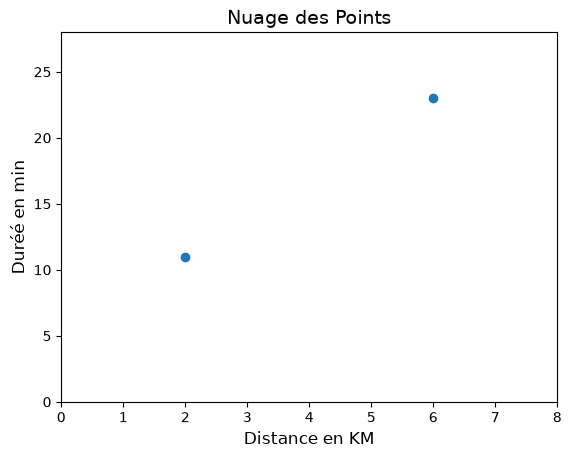

In [88]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([2, 6])
y = np.array([11, 23])
m = len(x)

plt.title("Nuage des Points", fontsize=14)
plt.scatter([x], [y])
plt.xlim(0, 8)
plt.ylim(0, 28)
plt.xlabel("Distance en KM", fontsize=12)
plt.ylabel("Duréé en min", fontsize=12)

In [87]:

# Calculons w avec les deux points

w = (y[1] - y[0]) / (x[1] - x[0])
print(f" w = {w}")

# Calculons b
b = y[0] - w * x[0]
print(f"la reponse de b est : {b}")

# Verification de b 
if b == y[1] - w * x[1]:
    print(f"La reponse de b = {b} est juste")
else:
    print("Recommencez à recalculer b")

# Verification de la formule directe
somme_xy = np.sum(x * y)
somme_x = np.sum(x)
somme_y = np.sum(y)
somme_x_carree = np.sum(x ** 2)
w_verification = (m * somme_xy - somme_x * somme_y) / (m * somme_x_carree - somme_x ** 2)
print("w:",w_verification)

# Calculons la prediction du modele sur les deux lignes
# Premiere ligne
y_prediction_1 = w*x[0] + b
print(f"La prediction de la premiere ligne est : {y_prediction_1}")
# Deuxieme Lignes
y_prediction_2 = w * x[1] + b
print(f"La prediction de la premiere ligne est : {y_prediction_2}")



 w = 3.0
la reponse de b est : 5.0
La reponse de b = 5.0 est juste
w: 3.0
La prediction de la premiere ligne est : 11.0
La prediction de la premiere ligne est : 23.0


In [85]:
#Calcul de l'erreur

e_1 = y[0] - y_prediction_1
e_2 = y[1] - y_prediction_2
print(f"Premiere erreur : {e_1}")
print(f"Deuxieme_erreur : {e_2}")

# Calcul de la MSE
mse = np.sum(e_1**2 + e_2**2) / m
print(f"La MSE est : {mse}")

# Calcul de la RMSE
rmse = np.sqrt(mse)
print(f"La RMSE est : {rmse}")

Premiere erreur : 0.0
Deuxieme_erreur : 0.0
La MSE est : 0.0
La RMSE est : 0.0


Je remarque que le modele n'a pas d'erreur elle est parfaite

In [86]:
#Prediction de la durée de la livraison de x = 4 et calculer son erreur
x_test = 4
y_test = 18 
y_prediction_test = w * x_test + b
print(y_prediction_test)

erreur_test = y_prediction_test - y_test
print(f"L'erreur est : {erreur_test}")

# Prediction de la durée de livraison pour x = 10
autre_x = 10

y_prediction_autre = w * autre_x + b

print(f"Autre prediction : {y_prediction_autre}")

# On ne peut pas calculer l'erreur de cette prediction car on n'a pas la duree reel

17.0
L'erreur est : -1.0
Autre prediction : 35.0


/tmp/ipykernel_96026/1571506556.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc="upper left", fontsize=10)


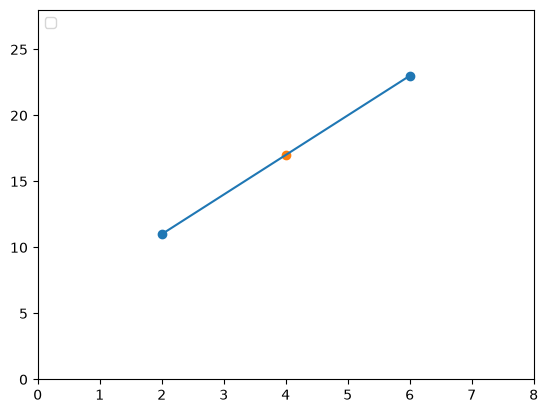

In [84]:
x_droite = np.array([0, 8])
y_droite = w * x_droite + b
plt.scatter(x, y)
plt.scatter(x_test, y_test)
plt.xlim(0, 8)
plt.ylim(0, 28)
plt.plot(x, y)
plt.legend(loc="upper left", fontsize=10)

1 - L'erreur d'aprentissage vaut 0 car le modele a bien predit les valeurs
2 - Oui cela prouve que le modele est bon
3 - Rien vu qu'on n'a deja le meilleur modele